<a href="https://colab.research.google.com/github/JacobSong1/MindWatch-IE08/blob/backend-dev/EDA/notebooks/MW_201_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import userdata
from pathlib import Path
import subprocess
import os

GITHUB_USERNAME = "bakai-work07"
REPO_URL = "https://github.com/JacobSong1/MindWatch-IE08.git"
REPO_DIR = Path("/content/MindWatch-IE08")
BASE_BRANCH = "backend-dev"

token = userdata.get("GITHUB_TOKEN")

if not token:
    raise ValueError("GITHUB_TOKEN was not found in Colab Secrets.")

# Keep credentials only in this temporary Colab runtime
subprocess.run(
    [
        "git", "config", "--global",
        "credential.helper", "cache --timeout=21600"
    ],
    check=True
)

credential = (
    "protocol=https\n"
    "host=github.com\n"
    f"username={GITHUB_USERNAME}\n"
    f"password={token}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

del token, credential

if (REPO_DIR / ".git").exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "fetch", "origin"],
        check=True
    )
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "switch", BASE_BRANCH],
        check=True
    )
    subprocess.run(
        [
            "git", "-C", str(REPO_DIR),
            "pull", "--ff-only", "origin", BASE_BRANCH
        ],
        check=True
    )
    print("Existing repository updated.")
else:
    subprocess.run(
        [
            "git", "clone",
            "--branch", BASE_BRANCH,
            REPO_URL,
            str(REPO_DIR)
        ],
        check=True
    )
    print("Repository cloned.")

EDA_DIR = REPO_DIR / "EDA"
os.chdir(EDA_DIR)

print("Working directory:", Path.cwd())

subprocess.run(["git", "branch", "--show-current"], check=True)
subprocess.run(["git", "status", "--short"], check=True)

Repository cloned.
Working directory: /content/MindWatch-IE08/EDA


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
!git status
!git branch --show-current
!ls

On branch backend-dev
Your branch is up to date with 'origin/backend-dev'.

nothing to commit, working tree clean
backend-dev
data  notebooks  README.md  requirements.txt


# MW-201: Exploratory Data Analysis

## Objective

This notebook examines wearable-derived physiological measures and
self-reported stress for one student. It evaluates data quality, temporal
patterns, relationships between measures, and potential physiological–
perceived stress mismatch.

In [ ]:
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

DATA_ROOT = Path(
    "/content/drive/MyDrive/MindWatch/SSAQS"
)

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_ROOT}")

participant_dirs = sorted(
    [
        path for path in DATA_ROOT.iterdir()
        if path.is_dir() and path.name.isdigit()
    ],
    key=lambda path: int(path.name)
)

print("Participant folders:", len(participant_dirs))
print("First folders:", [p.name for p in participant_dirs[:35]])

Mounted at /content/drive
Participant folders: 35
First folders: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35']


In [ ]:
import pandas as pd

EXPECTED_FILES = [
    "activity_level.csv",
    "daily_questions.csv",
    "hrv.csv",
    "oxygen.csv",
    "sleep.csv",
    "steps.csv",
    "stress.csv",
]

inventory_rows = []

for participant_dir in participant_dirs:
    for filename in EXPECTED_FILES:
        path = participant_dir / filename

        if path.exists():
            df = pd.read_csv(path)

            inventory_rows.append({
                "participant_id": participant_dir.name,
                "file": filename,
                "exists": True,
                "rows": len(df),
                "columns": len(df.columns),
                "duplicate_rows": int(df.duplicated().sum()),
            })
        else:
            inventory_rows.append({
                "participant_id": participant_dir.name,
                "file": filename,
                "exists": False,
                "rows": 0,
                "columns": 0,
                "duplicate_rows": None,
            })

inventory = pd.DataFrame(inventory_rows)

display(
    inventory.groupby("file").agg(
        participants_present=("exists", "sum"),
        total_rows=("rows", "sum"),
        median_rows=("rows", "median"),
        duplicate_rows=("duplicate_rows", "sum"),
    )
)

,participants_present,total_rows,median_rows,duplicate_rows
file,,,,
activity_level.csv,32,1766244,48506.0,0.0
daily_questions.csv,35,3133,103.0,0.0
hrv.csv,32,151243,4375.0,0.0
oxygen.csv,32,978367,27540.0,0.0
sleep.csv,32,1829,49.0,0.0
steps.csv,32,658894,18029.0,0.0
stress.csv,32,1777,49.0,0.0


In [ ]:
print((DATA_ROOT / "course-details.csv").exists())
print((DATA_ROOT / "users-courses.csv").exists())

True
True


In [ ]:
for filename in EXPECTED_FILES:
    examples = [
        participant_dir / filename
        for participant_dir in participant_dirs
        if (participant_dir / filename).exists()
    ]

    if not examples:
        print(f"\n{filename}: NOT FOUND")
        continue

    sample = pd.read_csv(examples[0])

    time_columns = [
        column for column in sample.columns
        if "time" in column.lower() or "date" in column.lower()
    ]

    print(f"\n--- {filename} ---")
    print("Columns:", sample.columns.tolist())
    print("Dtypes:")
    print(sample.dtypes.astype(str).to_dict())

    if time_columns:
        print("Timestamp samples:")
        print(sample[time_columns].head(3).to_dict("records"))


--- activity_level.csv ---
Columns: ['timestamp', 'level']
Dtypes:
{'timestamp': 'object', 'level': 'object'}
Timestamp samples:
[{'timestamp': '2025-02-21T12:58:00Z'}, {'timestamp': '2025-02-21T12:59:00Z'}, {'timestamp': '2025-02-21T13:00:00Z'}]

--- daily_questions.csv ---
Columns: ['timeStampScheduled', 'timeStampSent', 'timeStampStart', 'timeStampStop', 'originalTimeStampSent', 'timeZoneOffset', 'deltaUTC', 'stress', 'anxiety']
Dtypes:
{'timeStampScheduled': 'int64', 'timeStampSent': 'int64', 'timeStampStart': 'int64', 'timeStampStop': 'int64', 'originalTimeStampSent': 'int64', 'timeZoneOffset': 'int64', 'deltaUTC': 'int64', 'stress': 'int64', 'anxiety': 'int64'}
Timestamp samples:
[{'timeStampScheduled': 1739999335, 'timeStampSent': 1739999336, 'timeStampStart': 1740000118, 'timeStampStop': 1740000146, 'originalTimeStampSent': 0, 'timeZoneOffset': -21600}, {'timeStampScheduled': 1740082074, 'timeStampSent': 1740082078, 'timeStampStart': 1740082084, 'timeStampStop': 1740082096, 'o

In [ ]:
def load_participant_file(filename):
    frames = []

    for participant_dir in participant_dirs:
        path = participant_dir / filename

        if not path.exists():
            continue

        df = pd.read_csv(path)
        df.insert(0, "participant_id", participant_dir.name)
        frames.append(df)

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, ignore_index=True)


questions = load_participant_file("daily_questions.csv")
hrv = load_participant_file("hrv.csv")
sleep = load_participant_file("sleep.csv")
steps = load_participant_file("steps.csv")
activity = load_participant_file("activity_level.csv")
fitbit_stress = load_participant_file("stress.csv")
oxygen = load_participant_file("oxygen.csv")

In [ ]:
import pandas as pd
import numpy as np

# Work on copies so the raw loaded tables remain unchanged
questions = questions.copy()
hrv = hrv.copy()
sleep = sleep.copy()
steps = steps.copy()
activity = activity.copy()
fitbit_stress = fitbit_stress.copy()
oxygen = oxygen.copy()

In [ ]:
UNIX_COLUMNS = [
    "timeStampScheduled",
    "timeStampSent",
    "timeStampStart",
    "timeStampStop",
    "originalTimeStampSent",
]

for column in UNIX_COLUMNS:
    # Treat zero as a missing timestamp, not 1970-01-01
    valid_values = questions[column].where(questions[column] != 0)

    questions[f"{column}_utc"] = pd.to_datetime(
        valid_values,
        unit="s",
        utc=True,
        errors="coerce",
    )

questions["utc_offset"] = pd.to_timedelta(
    questions["timeZoneOffset"],
    unit="s",
)

questions["checkin_start_utc"] = questions["timeStampStart_utc"]
questions["checkin_stop_utc"] = questions["timeStampStop_utc"]

# Local wall-clock time using each record's UTC offset
questions["checkin_local"] = (
    questions["checkin_start_utc"] + questions["utc_offset"]
).dt.tz_localize(None)

questions["local_date"] = questions["checkin_local"].dt.normalize()

questions["checkin_duration_seconds"] = (
    questions["checkin_stop_utc"]
    - questions["checkin_start_utc"]
).dt.total_seconds()

display(
    questions[
        [
            "participant_id",
            "checkin_start_utc",
            "timeZoneOffset",
            "checkin_local",
            "local_date",
            "stress",
        ]
    ].head()
)

,participant_id,checkin_start_utc,timeZoneOffset,checkin_local,local_date,stress
0,1,2025-02-19 21:21:58+00:00,-21600,2025-02-19 15:21:58,2025-02-19,15
1,1,2025-02-20 20:08:04+00:00,-21600,2025-02-20 14:08:04,2025-02-20,33
2,1,2025-02-21 21:52:39+00:00,-21600,2025-02-21 15:52:39,2025-02-21,12
3,1,2025-02-22 21:36:12+00:00,-21600,2025-02-22 15:36:12,2025-02-22,9
4,1,2025-02-23 20:08:45+00:00,-21600,2025-02-23 14:08:45,2025-02-23,4


In [ ]:
for dataframe in [activity, steps, sleep, oxygen]:
    dataframe["timestamp_utc"] = pd.to_datetime(
        dataframe["timestamp"],
        utc=True,
        errors="coerce",
    )

In [ ]:
hrv["timestamp_naive"] = pd.to_datetime(
    hrv["timestamp"],
    errors="coerce",
)

hrv["provisional_date"] = hrv["timestamp_naive"].dt.normalize()

In [ ]:
fitbit_stress["fitbit_date"] = pd.to_datetime(
    fitbit_stress["DATE"],
    errors="coerce",
).dt.normalize()

fitbit_stress["updated_at_naive"] = pd.to_datetime(
    fitbit_stress["UPDATED_AT"],
    errors="coerce",
)

fitbit_stress["fitbit_stress_score"] = (
    fitbit_stress["STRESS_SCORE"].astype(float)
)

fitbit_stress.loc[
    fitbit_stress["CALCULATION_FAILED"],
    "fitbit_stress_score",
] = np.nan

In [ ]:
print("QUESTIONNAIRE TIMEZONE COMBINATIONS")
display(
    questions.groupby(
        ["timeZoneOffset", "deltaUTC"],
        dropna=False,
    )
    .size()
    .rename("rows")
    .reset_index()
    .sort_values("rows", ascending=False)
    .head(30)
)

print("\nACTIVITY LEVEL VALUES")
display(
    activity["level"]
    .value_counts(dropna=False)
    .rename_axis("level")
    .reset_index(name="rows")
)

print("\nFITBIT STRESS VALIDITY")
display(
    fitbit_stress.groupby(
        ["CALCULATION_FAILED", "STRESS_SCORE"],
        dropna=False,
    )
    .size()
    .rename("rows")
    .reset_index()
    .sort_values(
        ["CALCULATION_FAILED", "STRESS_SCORE"]
    )
)

print("\nHRV COVERAGE")
display(hrv["coverage"].describe())

print("\nHRV RMSSD")
display(hrv["rmssd"].describe())

print("\nSLEEP")
display(
    sleep[
        ["overall_score", "deep_sleep_in_minutes"]
    ].describe()
)

print("\nREPORTED STRESS")
display(questions["stress"].describe())

QUESTIONNAIRE TIMEZONE COMBINATIONS


,timeZoneOffset,deltaUTC,rows
16,-21600,0,2480
15,-21600,-1,418
14,-21600,-2,65
17,-21600,1,53
18,-21600,2,18
1,-25200,0,17
13,-21600,-3,9
19,-21600,3,6
23,-21600,11,5
40,7200,0,5



ACTIVITY LEVEL VALUES


,level,rows
0,SEDENTARY,1059736
1,LIGHTLY_ACTIVE,497944
2,MODERATELY_ACTIVE,123458
3,VERY_ACTIVE,85106



FITBIT STRESS VALIDITY


,CALCULATION_FAILED,STRESS_SCORE,rows
0,False,0,9
1,False,56,1
2,False,57,1
3,False,58,2
4,False,59,2
5,False,60,6
6,False,61,7
7,False,62,11
8,False,63,12
9,False,64,20


... (5 outputs left out)

,overall_score,deep_sleep_in_minutes
count,1829.000000,1829.000000
mean,75.547294,76.396391
std,8.282458,25.543369
min,40.000000,5.000000
25%,71.000000,59.000000
50%,76.000000,76.000000
75%,81.000000,93.000000
max,94.000000,177.000000



REPORTED STRESS


,stress
count,3133.000000
mean,33.232046
std,25.687347
min,0.000000
25%,13.000000
50%,26.000000
75%,49.000000
max,100.000000


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
quality_checks = pd.Series({
    "questionnaire_rows": len(questions),
    "questionnaire_participants":
        questions["participant_id"].nunique(),

    "missing_checkin_start":
        questions["checkin_start_utc"].isna().sum(),

    "stop_before_start":
        (
            questions["checkin_stop_utc"]
            < questions["checkin_start_utc"]
        ).sum(),

    "nonpositive_checkin_duration":
        (questions["checkin_duration_seconds"] <= 0).sum(),

    "duplicate_checkin_start":
        questions.duplicated(
            ["participant_id", "checkin_start_utc"]
        ).sum(),

    "missing_reported_stress":
        questions["stress"].isna().sum(),

    "stress_below_0":
        (questions["stress"] < 0).sum(),

    "stress_above_100":
        (questions["stress"] > 100).sum(),

    "unparsed_activity_timestamp":
        activity["timestamp_utc"].isna().sum(),

    "unparsed_steps_timestamp":
        steps["timestamp_utc"].isna().sum(),

    "unparsed_sleep_timestamp":
        sleep["timestamp_utc"].isna().sum(),

    "unparsed_hrv_timestamp":
        hrv["timestamp_naive"].isna().sum(),

    "nonpositive_hrv":
        (hrv["rmssd"] <= 0).sum(),

    "failed_fitbit_scores":
        fitbit_stress["CALCULATION_FAILED"].sum(),

    "nonfailed_zero_fitbit_scores":
        (
            (~fitbit_stress["CALCULATION_FAILED"])
            & (fitbit_stress["STRESS_SCORE"] == 0)
        ).sum(),
})

display(quality_checks.to_frame("value"))

,value
questionnaire_rows,3133
questionnaire_participants,35
missing_checkin_start,0
stop_before_start,0
nonpositive_checkin_duration,0
duplicate_checkin_start,0
missing_reported_stress,0
stress_below_0,0
stress_above_100,0
unparsed_activity_timestamp,0


In [ ]:
questionnaire_frequency = (
    questions.groupby(
        ["participant_id", "local_date"]
    )
    .size()
    .rename("checkins_per_day")
    .reset_index()
)

print("Check-ins per participant-day:")
display(
    questionnaire_frequency["checkins_per_day"]
    .value_counts()
    .sort_index()
    .rename_axis("checkins_per_day")
    .reset_index(name="participant_days")
)

print("Check-in local hour distribution:")
display(
    questions["checkin_local"]
    .dt.hour
    .value_counts()
    .sort_index()
    .rename_axis("local_hour")
    .reset_index(name="checkins")
)

Check-ins per participant-day:


,checkins_per_day,participant_days
0,1,3131
1,2,1


Check-in local hour distribution:


,local_hour,checkins
0,0,1
1,6,1
2,12,2
3,13,8
4,14,780
5,15,1436
6,16,684
7,17,195
8,18,20
9,19,2


In [17]:
# Unique identifier for each questionnaire/check-in
questions = questions.reset_index(drop=True)
questions["checkin_id"] = np.arange(len(questions))

# Actual UTC time corresponding to local midnight
questions["local_day_start_utc"] = (
    pd.to_datetime(
        questions["local_date"],
        utc=True,
    )
    - questions["utc_offset"]
)

# HRV: nonpositive RMSSD cannot be physiologically interpreted
hrv["rmssd_clean"] = hrv["rmssd"].where(
    hrv["rmssd"] > 0
)

# Sleep rows without parseable timestamps cannot be aligned
sleep["valid_timestamp"] = sleep["timestamp_utc"].notna()

# Fitbit comparator: failed calculations are missing
fitbit_stress["fitbit_stress_score_clean"] = (
    fitbit_stress["STRESS_SCORE"].astype(float)
)

fitbit_stress.loc[
    fitbit_stress["CALCULATION_FAILED"],
    "fitbit_stress_score_clean",
] = np.nan

In [18]:
print("UNPARSEABLE SLEEP TIMESTAMPS")
display(
    sleep.loc[
        sleep["timestamp_utc"].isna(),
        [
            "participant_id",
            "timestamp",
            "overall_score",
            "deep_sleep_in_minutes",
        ],
    ]
)

print("\nNONPOSITIVE HRV VALUES")
display(
    hrv.loc[
        hrv["rmssd"] <= 0,
        [
            "participant_id",
            "timestamp",
            "rmssd",
            "coverage",
        ],
    ]
)

print("\nNON-FAILED FITBIT ZERO SCORES")
display(
    fitbit_stress.loc[
        (~fitbit_stress["CALCULATION_FAILED"])
        & (fitbit_stress["STRESS_SCORE"] == 0),
        [
            "participant_id",
            "DATE",
            "STRESS_SCORE",
            "CALCULATION_FAILED",
        ],
    ]
)

print("\nHRV COVERAGE OUTSIDE 0–1")
display(
    pd.Series({
        "coverage_below_0": (hrv["coverage"] < 0).sum(),
        "coverage_above_1": (hrv["coverage"] > 1).sum(),
        "coverage_missing": hrv["coverage"].isna().sum(),
    }).to_frame("rows")
)

UNPARSEABLE SLEEP TIMESTAMPS


,participant_id,timestamp,overall_score,deep_sleep_in_minutes
877,20,2025-05-12T07:59:28.463Z,67,77
886,20,2025-05-28T10:58:05.456Z,79,124
1268,27,2025-04-07T06:05:31.442Z,77,46
1272,27,2025-04-11T06:59:41.713Z,81,62
1276,27,2025-04-15T06:29:32.632Z,77,64
1287,27,2025-04-28T05:48:18.223Z,73,46
1291,27,2025-05-02T08:20:01.774Z,77,71



NONPOSITIVE HRV VALUES


,participant_id,timestamp,rmssd,coverage
1876,1,2025-04-04T04:55:00,0.0,0.800
2324,1,2025-04-18T00:20:00,0.0,0.709
3892,4,2025-02-27T07:25:00,0.0,0.704
58641,17,2025-03-05T07:20:00,0.0,0.751
58642,17,2025-03-05T07:25:00,0.0,0.902
71903,20,2025-05-04T02:55:00,0.0,0.710
101512,26,2025-05-13T22:05:00,0.0,0.739
115524,28,2025-05-23T01:45:00,0.0,0.702
124920,30,2025-05-09T05:50:00,0.0,0.707
136310,33,2025-04-17T08:10:00,0.0,0.705



NON-FAILED FITBIT ZERO SCORES


,participant_id,DATE,STRESS_SCORE,CALCULATION_FAILED
71,5,2025-03-25T00:00:00,0,False
206,7,2025-03-25T00:00:00,0,False
288,8,2025-03-25T00:00:00,0,False
610,16,2025-03-25T00:00:00,0,False
681,18,2025-03-25T00:00:00,0,False
975,24,2025-03-25T00:00:00,0,False
1116,26,2025-03-25T00:00:00,0,False
1408,30,2025-03-25T00:00:00,0,False
1519,32,2025-03-25T00:00:00,0,False



HRV COVERAGE OUTSIDE 0–1


,rows
coverage_below_0,0
coverage_above_1,42332
coverage_missing,0


In [19]:
offset_summary = (
    questions.groupby("participant_id")
    .agg(
        questionnaire_rows=("checkin_id", "size"),
        number_of_offsets=("timeZoneOffset", "nunique"),
        offsets=(
            "timeZoneOffset",
            lambda values: sorted(values.unique().tolist()),
        ),
        first_checkin=("checkin_start_utc", "min"),
        last_checkin=("checkin_start_utc", "max"),
    )
    .reset_index()
)

display(
    offset_summary.sort_values(
        ["number_of_offsets", "participant_id"],
        ascending=[False, True],
    )
)

print("Records not using UTC-6:")
display(
    questions.loc[
        questions["timeZoneOffset"] != -21600,
        [
            "participant_id",
            "checkin_start_utc",
            "timeZoneOffset",
            "deltaUTC",
            "checkin_local",
        ],
    ].sort_values(
        ["participant_id", "checkin_start_utc"]
    )
)

,participant_id,questionnaire_rows,number_of_offsets,offsets,first_checkin,last_checkin
0,1,121,2,"[-25200, -21600]",2025-02-19 21:21:58+00:00,2025-06-22 21:12:29+00:00
2,11,39,2,"[-25200, -21600]",2025-02-25 21:43:27+00:00,2025-05-15 21:16:41+00:00
6,15,59,2,"[-21600, -18000]",2025-02-24 22:12:54+00:00,2025-06-07 21:36:23+00:00
7,16,71,2,"[-21600, -14400]",2025-02-17 20:57:02+00:00,2025-06-19 20:45:43+00:00
10,19,116,2,"[-25200, -21600]",2025-02-19 22:15:19+00:00,2025-06-23 21:18:24+00:00
12,20,100,2,"[-25200, -21600]",2025-02-19 21:37:45+00:00,2025-06-20 20:19:33+00:00
18,26,102,2,"[-21600, 7200]",2025-03-06 21:07:02+00:00,2025-07-02 20:57:00+00:00
29,4,118,2,"[-25200, -21600]",2025-02-14 21:07:47+00:00,2025-06-13 20:31:03+00:00
33,8,104,2,"[-25200, -21600]",2025-02-17 21:01:56+00:00,2025-06-11 22:34:31+00:00
1,10,115,1,[-21600],2025-02-20 21:10:06+00:00,2025-06-22 22:45:03+00:00


Records not using UTC-6:


,participant_id,checkin_start_utc,timeZoneOffset,deltaUTC,checkin_local
46,1,2025-04-08 19:39:37+00:00,-25200,-1,2025-04-08 12:39:37
47,1,2025-04-09 22:04:31+00:00,-25200,0,2025-04-09 15:04:31
48,1,2025-04-10 20:04:18+00:00,-25200,0,2025-04-10 13:04:18
1001,11,2025-04-13 20:22:32+00:00,-25200,0,2025-04-13 13:22:32
1002,11,2025-04-14 20:19:50+00:00,-25200,0,2025-04-14 13:19:50
1235,15,2025-04-16 22:21:27+00:00,-18000,2,2025-04-16 17:21:27
1236,15,2025-04-18 21:29:34+00:00,-18000,1,2025-04-18 16:29:34
1237,15,2025-04-19 21:05:06+00:00,-18000,0,2025-04-19 16:05:06
1290,16,2025-04-11 23:44:50+00:00,-14400,0,2025-04-11 19:44:50
1291,16,2025-04-12 23:26:19+00:00,-14400,0,2025-04-12 19:26:19


In [20]:
activity_sorted = activity.sort_values(
    ["participant_id", "timestamp_utc"]
).copy()

activity_sorted["interval_minutes"] = (
    activity_sorted.groupby("participant_id")[
        "timestamp_utc"
    ]
    .diff()
    .dt.total_seconds()
    .div(60)
)

display(
    activity_sorted.loc[
        activity_sorted["interval_minutes"].between(0, 10),
        "interval_minutes",
    ].value_counts().sort_index().head(15)
)

,count
interval_minutes,
0.016667,6
0.050000,1
0.066667,6
0.083333,2
0.100000,5
0.116667,5
0.133333,3
0.150000,5
0.166667,1


In [21]:
modal_offsets = (
    questions.groupby("participant_id")["timeZoneOffset"]
    .agg(lambda values: values.mode().iloc[0])
    .rename("modal_offset_seconds")
)

hrv_time_audit = hrv.merge(
    modal_offsets,
    on="participant_id",
    how="left",
)

hrv_time_audit["modal_offset"] = pd.to_timedelta(
    hrv_time_audit["modal_offset_seconds"],
    unit="s",
)

# Hypothesis A: the stored HRV timestamp is local wall-clock time
hrv_time_audit["hour_if_local"] = (
    hrv_time_audit["timestamp_naive"].dt.hour
)

# Hypothesis B: the stored HRV timestamp is UTC without the Z suffix
hrv_time_audit["local_time_if_utc"] = (
    hrv_time_audit["timestamp_naive"].dt.tz_localize("UTC")
    + hrv_time_audit["modal_offset"]
)

hrv_time_audit["hour_if_utc"] = (
    hrv_time_audit["local_time_if_utc"].dt.hour
)

display(
    pd.DataFrame({
        "stored_as_local": (
            hrv_time_audit["hour_if_local"]
            .value_counts()
            .sort_index()
        ),
        "stored_as_utc": (
            hrv_time_audit["hour_if_utc"]
            .value_counts()
            .sort_index()
        ),
    }).fillna(0)
)

,stored_as_local,stored_as_utc
0,11123,13715
1,15996,10107
2,18714,6777
3,20045,4173
4,20487,2167
5,17773,971
6,13715,517
7,10107,273
8,6777,140
9,4173,77


In [22]:
analysis = questions[
    [
        "checkin_id",
        "participant_id",
        "checkin_start_utc",
        "checkin_local",
        "local_date",
        "local_day_start_utc",
        "utc_offset",
        "stress",
    ]
].copy()

print("Analysis rows:", len(analysis))
print("Participants:", analysis["participant_id"].nunique())

Analysis rows: 3133
Participants: 35


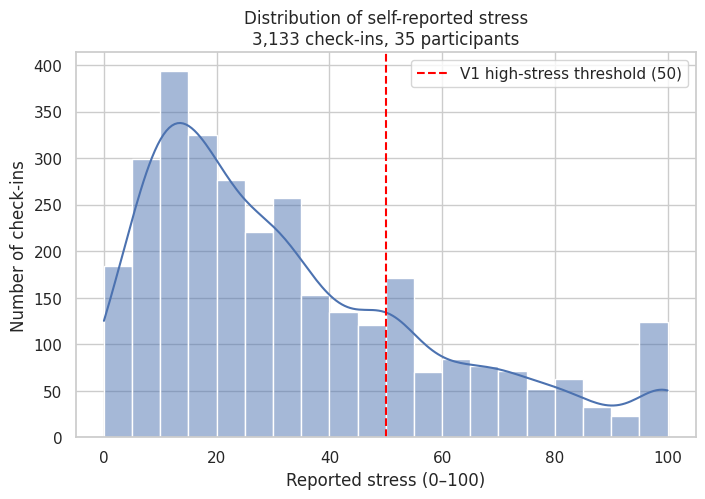

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

sns.histplot(
    data=analysis,
    x="stress",
    bins=20,
    kde=True,
)

plt.axvline(
    50,
    color="red",
    linestyle="--",
    label="V1 high-stress threshold (50)",
)

plt.title(
    "Distribution of self-reported stress\n"
    f"{len(analysis):,} check-ins, "
    f"{analysis['participant_id'].nunique()} participants"
)
plt.xlabel("Reported stress (0–100)")
plt.ylabel("Number of check-ins")
plt.legend()
plt.show()

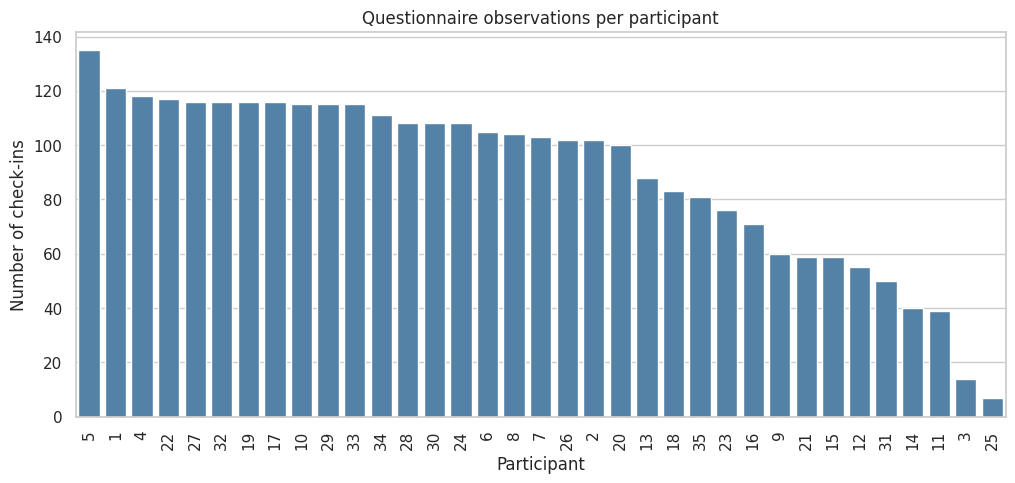

,checkins
count,35.000000
mean,89.514286
std,32.342261
min,7.000000
25%,65.500000
50%,103.000000
75%,115.000000
max,135.000000


In [24]:
observations_per_participant = (
    analysis.groupby("participant_id")
    .size()
    .sort_values(ascending=False)
    .rename("checkins")
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=observations_per_participant,
    x="participant_id",
    y="checkins",
    color="steelblue",
)

plt.title("Questionnaire observations per participant")
plt.xlabel("Participant")
plt.ylabel("Number of check-ins")
plt.xticks(rotation=90)
plt.show()

display(observations_per_participant.describe())

In [25]:
threshold_results = []

for threshold in [40, 50, 60]:
    high = analysis["stress"] >= threshold

    threshold_results.append({
        "threshold": threshold,
        "high_stress_checkins": int(high.sum()),
        "percentage": high.mean() * 100,
        "participants_with_high_stress": (
            analysis.loc[high, "participant_id"].nunique()
        ),
    })

display(pd.DataFrame(threshold_results))

,threshold,high_stress_checkins,percentage,participants_with_high_stress
0,40,1024,32.684328,35
1,50,768,24.513246,35
2,60,527,16.820938,34
